# Best/Worst Direct Scan (Brute Force)

This notebook traverses all dataset samples, evaluates the BCLF objective directly, finds the best/worst sample, and plots S21/S11 with band overlays.

In [5]:
from __future__ import annotations

from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

sys.path.insert(0, str(REPO_ROOT / 'src'))

from optimization.datasets import BCLFDataset
from optimization.optimization_spec import BCLFOptimizationSpec

In [6]:
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
if not DATASET_PATH.exists():
    DATASET_PATH = REPO_ROOT / 'data' / 'bclf_dataset.pkl'

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
freq_cfg = cfg['data']['freqs']
freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)

dataset = BCLFDataset.from_pickle(DATASET_PATH, freqs=freqs)
spec = BCLFOptimizationSpec(
    passband_ghz=(5.2, 5.9),
    lower_stopband_ghz=(3.6, 4.8),
    upper_stopband_ghz=(6.5, 8.7),
    min_passband_s21_db=-7.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-18.0,
    s11_weight=0.5,
    stopband_weight=0.5,
    penalty_weight=5.0,
)
objective = spec.to_objective()

print('repo root:', REPO_ROOT)
print('dataset:', DATASET_PATH)
print('dataset size:', len(dataset))
print('objective:')
print(json.dumps(objective.describe(), indent=2, ensure_ascii=False))

repo root: /home/zhanghf/projects/vector
dataset: /home/zhanghf/projects/vector/data/filter_bnn_online_uaw_uaw_dataset.pkl
dataset size: 1323
objective:
{
  "type": "objective_function",
  "minimize": true,
  "terms": [
    {
      "name": "score_a_mean_passband_s21",
      "kind": "MaximizeMetric",
      "metric": "s21_mean_5200000000_5900000000",
      "weight": 1.0
    },
    {
      "name": "score_b_mean_passband_s11",
      "kind": "MinimizeMetric",
      "metric": "s11_mean_5200000000_5900000000",
      "weight": 0.5
    },
    {
      "name": "score_c_mean_stopband_s21",
      "kind": "MinimizeMetric",
      "metric": "s21_mean_union_3600000000_4800000000__6500000000_8700000000",
      "weight": 0.5
    },
    {
      "name": "penalty_a_worst_passband_s21",
      "kind": "LowerBoundHingePenalty",
      "metric": "s21_min_5200000000_5900000000",
      "weight": 5.0
    },
    {
      "name": "penalty_b_worst_passband_s11",
      "kind": "UpperBoundHingePenalty",
      "metric": "

In [7]:
rows = []
for idx in range(len(dataset)):
    geo = dataset.get_geometry(idx)
    f, s = dataset.get_response_by_geometry(geo)
    out = objective.evaluate(f, s)

    m = out.metrics
    a_mean = m.get('s21_mean_5200000000_5900000000', np.nan)
    b_mean = m.get('s11_mean_5200000000_5900000000', np.nan)
    c_mean = m.get('s21_mean_union_3600000000_4800000000__6500000000_8700000000', np.nan)
    a_worst = m.get('s21_min_5200000000_5900000000', np.nan)
    b_worst = m.get('s11_max_5200000000_5900000000', np.nan)
    c_worst = m.get('s21_max_union_3600000000_4800000000__6500000000_8700000000', np.nan)

    s_score = a_mean - 0.5 * b_mean - 0.5 * c_mean
    p = max(0.0, -7.0 - a_worst) + max(0.0, b_worst + 7.0) + max(0.0, c_worst + 18.0)
    J = s_score - 5.0 * p

    rows.append({
        'dataset_index': idx,
        'case_id': dataset.get_case_id(idx),
        'objective_minimize': float(out.objective),
        'J_maximize': float(J),
        'S_score': float(s_score),
        'P': float(p),
    })

scan_df = pd.DataFrame(rows)
scan_df = scan_df.sort_values('objective_minimize').reset_index(drop=True)
scan_df.head(10)

,dataset_index,case_id,objective_minimize,J_maximize,S_score,P
0,60,60,-28.857492,28.857492,28.857492,0.0
1,61,61,-28.564737,28.564737,28.564737,0.0
2,160,160,-28.355755,28.355755,28.355755,0.0
3,151,151,-28.355151,28.355151,28.355151,0.0
4,180,180,-28.106335,28.106335,28.106335,0.0
5,777,777,-27.749223,27.749223,27.749223,0.0
6,581,581,-27.595688,27.595688,27.595688,0.0
7,372,372,-27.564848,27.564848,27.564848,0.0
8,62,62,-27.423711,27.423711,27.423711,0.0
9,181,181,-27.355873,27.355873,27.355873,0.0


In [8]:
best_row = scan_df.iloc[0]
worst_row = scan_df.iloc[-1]

best_idx = int(best_row['dataset_index'])
worst_idx = int(worst_row['dataset_index'])

print('BEST (min objective / max J)')
print(best_row)
print('\nWORST')
print(worst_row)

BEST (min objective / max J)
dataset_index                60
case_id                      60
objective_minimize   -28.857492
J_maximize            28.857492
S_score               28.857492
P                           0.0
Name: 0, dtype: object

WORST
dataset_index              1011
case_id                    1011
objective_minimize    92.269162
J_maximize           -92.269162
S_score                18.58357
P                     22.170546
Name: 1322, dtype: object


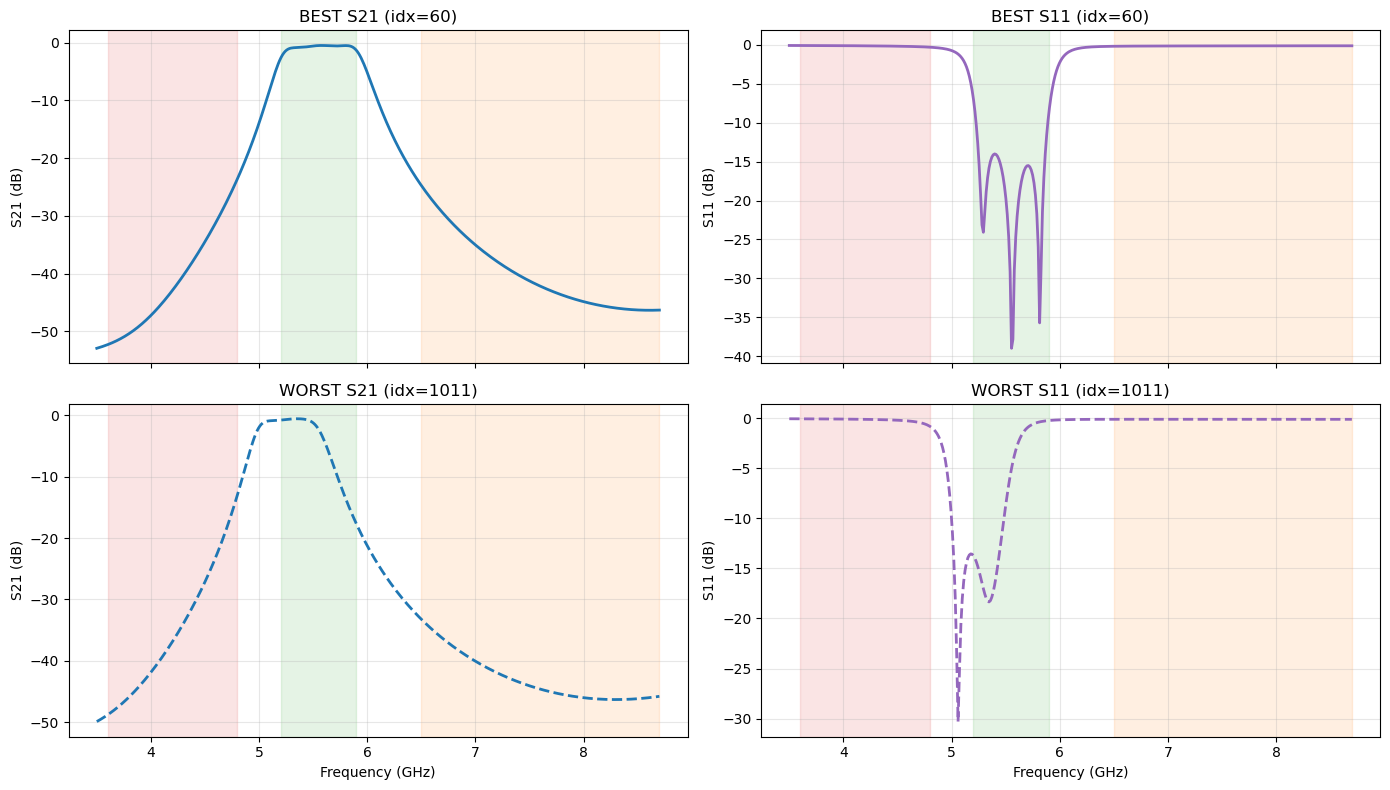

In [9]:
def _load_curve(idx: int):
    geo = dataset.get_geometry(idx)
    f, s = dataset.get_response_by_geometry(geo)
    f_ghz = f / 1e9
    s11 = 20.0 * np.log10(np.maximum(np.abs(s[0, 0, :]), 1e-15))
    s21 = 20.0 * np.log10(np.maximum(np.abs(s[1, 0, :]), 1e-15))
    return f_ghz, s11, s21

bp = spec.frequency_bands_ghz['passband']
lsl = spec.frequency_bands_ghz['lower_stopband']
usl = spec.frequency_bands_ghz['upper_stopband']

fb, s11b, s21b = _load_curve(best_idx)
fw, s11w, s21w = _load_curve(worst_idx)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for ax in axes.ravel():
    ax.axvspan(lsl[0], lsl[1], color='tab:red', alpha=0.12)
    ax.axvspan(bp[0], bp[1], color='tab:green', alpha=0.12)
    ax.axvspan(usl[0], usl[1], color='tab:orange', alpha=0.12)
    ax.grid(True, alpha=0.3)

axes[0, 0].plot(fb, s21b, color='tab:blue', lw=2)
axes[0, 0].set_title(f'BEST S21 (idx={best_idx})')
axes[0, 0].set_ylabel('S21 (dB)')

axes[0, 1].plot(fb, s11b, color='tab:purple', lw=2)
axes[0, 1].set_title(f'BEST S11 (idx={best_idx})')
axes[0, 1].set_ylabel('S11 (dB)')

axes[1, 0].plot(fw, s21w, color='tab:blue', lw=2, linestyle='--')
axes[1, 0].set_title(f'WORST S21 (idx={worst_idx})')
axes[1, 0].set_xlabel('Frequency (GHz)')
axes[1, 0].set_ylabel('S21 (dB)')

axes[1, 1].plot(fw, s11w, color='tab:purple', lw=2, linestyle='--')
axes[1, 1].set_title(f'WORST S11 (idx={worst_idx})')
axes[1, 1].set_xlabel('Frequency (GHz)')
axes[1, 1].set_ylabel('S11 (dB)')

plt.tight_layout()
plt.show()

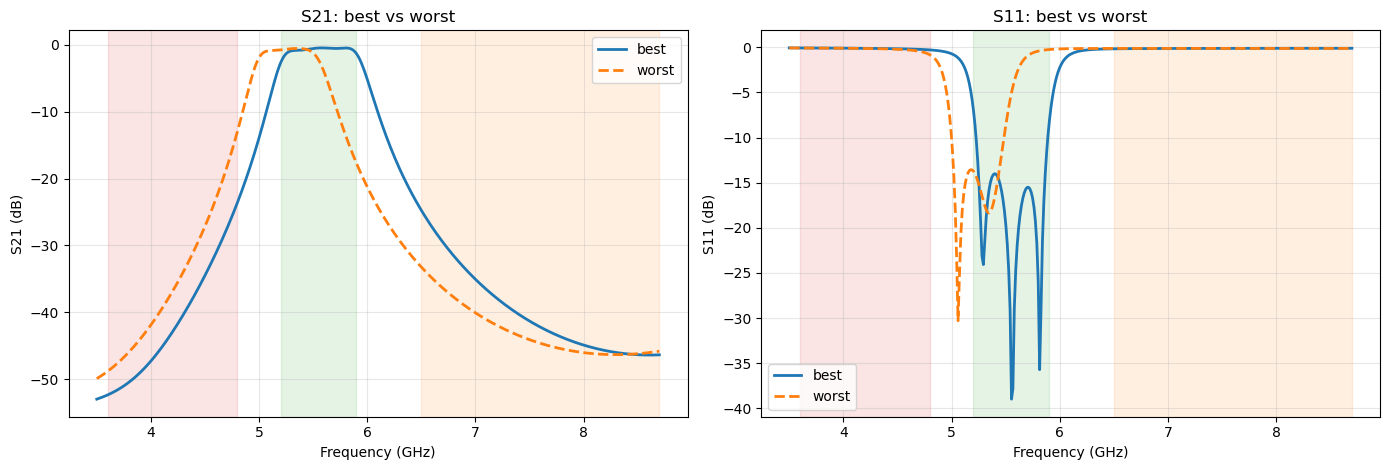

In [10]:
# Optional: overlay best vs worst directly
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)

for ax in axes:
    ax.axvspan(lsl[0], lsl[1], color='tab:red', alpha=0.12)
    ax.axvspan(bp[0], bp[1], color='tab:green', alpha=0.12)
    ax.axvspan(usl[0], usl[1], color='tab:orange', alpha=0.12)
    ax.grid(True, alpha=0.3)

axes[0].plot(fb, s21b, label='best', lw=2)
axes[0].plot(fw, s21w, label='worst', lw=2, linestyle='--')
axes[0].set_title('S21: best vs worst')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[0].legend()

axes[1].plot(fb, s11b, label='best', lw=2)
axes[1].plot(fw, s11w, label='worst', lw=2, linestyle='--')
axes[1].set_title('S11: best vs worst')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 (dB)')
axes[1].legend()

plt.tight_layout()
plt.show()